# Analyzing results for Spatial Navigation

## Imports and configuration

In [1]:
import json
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import os
import pathlib
import pickle
from scipy.stats import ttest_rel
import sys
from tqdm import tqdm

import torch

from plots import plot_pos, scatter_pos, stemplot, violinplot, add_border_and_ticks
from helpers import optimal_decoder, gather_models, gather_test_data, momentum, \
                    dict_to_csv, wd_types_to_csvs, array_to_heatmap
from metrics import wasserstein, calc_wds#, calc_kls

os.makedirs('pickle', exist_ok=True)
replay_dict_path = 'pickle/replay_biased.pkl'

## Load models and data

In [2]:
# Hyperparameters
unmask_every = 3
epoch = 15000 
#epoch = 5000 #2500
t_quiescent = 500 #1000 #1000 #250 #100
quiescence = "same" 
lambda_scaling = False

In [3]:
results = pathlib.Path("../results")
noise = 0.0001
config_name = f"noisy_biased_unmask_every_{unmask_every}_{noise}"
seed_dirs = [results / "spatial_navigation" / f \
             for f in os.listdir(results / "spatial_navigation") if config_name in f]
seed_dirs

[PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_6'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_8'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_1'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_2'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_3'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_7'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_0'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_5'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_9'),
 PosixPath('../results/spatial_navigation/noisy_biased_unmask_every_3_0.0001_4')]

In [4]:
# Load models and their test data
models = gather_models(seed_dirs, epoch)
test_obs, test_pos, test_inits = gather_test_data(models)

## Simulating the model with various parameters

In [5]:
tau_a = 50
lambda_v_vals = [1, 0.7, 0.5, 0.3]
b_a_vals = [0, 0.01, 0.02, 0.03] # around 0.04 is where the "inner circle" breaks

In [6]:
replay = {}
quiescent_inputs = torch.zeros(models[0].task.batch_size, t_quiescent, 2)
for lambda_v in lambda_v_vals:
    for b_a in b_a_vals:
        key = str({'lambda_v': lambda_v, 'tau_a': tau_a, 'b_a': b_a})
        print(key)        
        replay[key] = []
        for (model, init) in zip(models, test_inits):
            # Implausible momentum
            pc_act = momentum(
                model, lambda_v=lambda_v, tau_a=tau_a, b_a=b_a, quiescence=quiescence,
                lambda_scaling=lambda_scaling, x=quiescent_inputs, init_state=init)[1]
            replay[key].append(optimal_decoder(
                model, pc_act, lr=(2e-1 if quiescence=='scaled' else 1e-1),
                verbose=True, iters=51))
        replay[key] = torch.stack(replay[key])

{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}
0 2.149450665456243e-06
5 1.4770606640013284e-06
10 1.1693215355990105e-06
15 1.0719413694459945e-06
20 1.0596826314213104e-06
25 1.0640939080985845e-06
30 1.0634204272719217e-06
35 1.058206521520333e-06
40 1.0531632597121643e-06
45 1.0503454177523963e-06
50 1.0493203035366605e-06
0 1.5028798543426092e-06
5 1.05314700249437e-06
10 8.347855668944248e-07
15 7.513762056987616e-07
20 7.297184083654429e-07
25 7.275285724972491e-07
30 7.274812219293381e-07
35 7.259267817971704e-07
40 7.237779868773941e-07
45 7.220920679174014e-07
50 7.211058346001664e-07
0 1.4549719935530447e-06
5 1.016285295918351e-06
10 8.05799800218665e-07
15 7.271358413163398e-07
20 7.074111181282206e-07
25 7.054858883748238e-07
30 7.050123826957133e-07
35 7.028643267403822e-07
40 7.002250299592561e-07
45 6.982826903367823e-07
50 6.972690584916563e-07
0 1.3961965805719956e-06
5 9.652545713834115e-07
10 7.490692155442957e-07
15 6.601439963560551e-07
20 6.334477120617521e-07
25 6.2989

10 1.7575308675077395e-06
15 1.5102129964361666e-06
20 1.4296239214672823e-06
25 1.417586986462993e-06
30 1.420097305526724e-06
35 1.4188575505613699e-06
40 1.4135265473669278e-06
45 1.4079289485380286e-06
50 1.4042205975783872e-06
{'lambda_v': 1, 'tau_a': 100, 'b_a': 5}
0 3.467940587142948e-06
5 3.126080855508917e-06
10 2.9393377189990133e-06
15 2.852349325621617e-06
20 2.81792404166481e-06
25 2.805448730214266e-06
30 2.7998846690024948e-06
35 2.796064109134022e-06
40 2.7931182557949796e-06
45 2.7911592042073607e-06
50 2.7900996428797953e-06
0 2.0204940938128857e-06
5 1.9021341586267226e-06
10 1.8294761048309738e-06
15 1.7884293583847466e-06
20 1.7670938632363686e-06
25 1.7567889472047682e-06
30 1.752012963152083e-06
35 1.7497393400844885e-06
40 1.7485282342022401e-06
45 1.7477885876360233e-06
50 1.747305987009895e-06
0 4.614938916347455e-06
5 3.4955355658894405e-06
10 2.89846093437518e-06
15 2.6339664600527612e-06
20 2.5389726943103597e-06
25 2.5116517008427763e-06
30 2.5036629267560

25 9.216816465595912e-07
30 9.2223956471571e-07
35 9.223219876730582e-07
40 9.21428920719336e-07
45 9.202435649058316e-07
50 9.193023515763343e-07
0 2.4624118850624654e-06
5 1.5719388102297671e-06
10 1.0943859933831845e-06
15 9.011380370793631e-07
20 8.5500897739621e-07
25 8.568986231693998e-07
30 8.60702186855633e-07
35 8.570191880608036e-07
40 8.502572086399596e-07
45 8.449346751149278e-07
50 8.422045425504621e-07
{'lambda_v': 0.8, 'tau_a': 100, 'b_a': 3}
0 2.7940980089624645e-06
5 2.161034672099049e-06
10 1.8488738078303868e-06
15 1.7238381815332104e-06
20 1.6833745348776574e-06
25 1.6709527699276805e-06
30 1.6646743006276665e-06
35 1.659775193729729e-06
40 1.6564196130275377e-06
45 1.6546767938052653e-06
50 1.653918161537149e-06
0 1.4744489362783497e-06
5 1.298887696066231e-06
10 1.1971293361057178e-06
15 1.1446334156062221e-06
20 1.1209289141334011e-06
25 1.1116870837213355e-06
30 1.1084972584285424e-06
35 1.107299226532632e-06
40 1.1065739045079681e-06
45 1.1059614735131618e-06
5

30 8.587405773141654e-07
35 8.555732051718223e-07
40 8.523035717189487e-07
45 8.502607897753478e-07
50 8.493041150359204e-07
0 1.399998041051731e-06
5 1.0966018635372166e-06
10 9.409193921783299e-07
15 8.759867569096969e-07
20 8.565357347833924e-07
25 8.541758234059671e-07
30 8.55239704833366e-07
35 8.5535526750391e-07
40 8.543467515664815e-07
45 8.530656714356155e-07
50 8.520915457665978e-07
0 2.2011963665136136e-06
5 1.3468975339492317e-06
10 9.224314112543652e-07
15 7.713931609032443e-07
20 7.450395287378342e-07
25 7.496664693462662e-07
30 7.500973424612312e-07
35 7.439461455760465e-07
40 7.371378956122498e-07
45 7.329618938456406e-07
50 7.31259603981016e-07
{'lambda_v': 0.6, 'tau_a': 100, 'b_a': 1}
0 2.3340621737588663e-06
5 1.674626332714979e-06
10 1.3494433233063319e-06
15 1.226589915859222e-06
20 1.19693811484467e-06
25 1.1953035254919087e-06
30 1.1953137573073036e-06
35 1.1922622888960177e-06
40 1.188346573144372e-06
45 1.1854926924570464e-06
50 1.1839861144835595e-06
0 1.40368

35 1.798201765268459e-06
40 1.7978376263272366e-06
45 1.7973820831684861e-06
50 1.7969432519748807e-06
0 2.7780179152614437e-06
5 2.6372820229880745e-06
10 2.5486967842880404e-06
15 2.498601133993361e-06
20 2.473644144629361e-06
25 2.462839574945974e-06
30 2.4587773168605054e-06
35 2.457401706124074e-06
40 2.4569203560531605e-06
45 2.456695938235498e-06
50 2.456543597872951e-06
0 2.7272501483821543e-06
5 2.525206809878e-06
10 2.3913803488539997e-06
15 2.3083593987394124e-06
20 2.260373548779171e-06
25 2.234740577478078e-06
30 2.2222452571440954e-06
35 2.216787379438756e-06
40 2.21469895222981e-06
45 2.2140036435303045e-06
50 2.213774678239133e-06
0 4.725202870758949e-06
5 3.5923794712289236e-06
10 2.8587280667125015e-06
15 2.4679700345586753e-06
20 2.312250217073597e-06
25 2.276672830703319e-06
30 2.2795077256887453e-06
35 2.2827975953987334e-06
40 2.2788128717365908e-06
45 2.2715867089573294e-06
50 2.265521516164881e-06
{'lambda_v': 0.5, 'tau_a': 100, 'b_a': 0}
0 2.4113348899845732e-0

50 1.1255780236751889e-06
0 1.9056079736401443e-06
5 1.5512107438553357e-06
10 1.3724842347073718e-06
15 1.2977802725799847e-06
20 1.2737745009872015e-06
25 1.2688628885371145e-06
30 1.268458390768501e-06
35 1.267917696168297e-06
40 1.2667971986957127e-06
45 1.2656300896196626e-06
50 1.2647603853110923e-06
0 2.1192424810578814e-06
5 1.8992366221937118e-06
10 1.7718942899591639e-06
15 1.7102602214436047e-06
20 1.6866415535332635e-06
25 1.6799197055661352e-06
30 1.6784025547167403e-06
35 1.6776609754742822e-06
40 1.6768605064498843e-06
45 1.6761563301770366e-06
50 1.6756678178353468e-06
0 1.952460024767788e-06
5 1.779184231054387e-06
10 1.6759994423409807e-06
15 1.6206279269681545e-06
20 1.594234845470055e-06
25 1.5833060160730383e-06
30 1.5794994396856055e-06
35 1.5784007700858638e-06
40 1.5780624380568042e-06
45 1.5778274473632337e-06
50 1.577576995259733e-06
0 3.508479494485073e-06
5 2.4636194666527444e-06
10 1.864196974565857e-06
15 1.5877286614340846e-06
20 1.4979639217926888e-06
25

In [7]:
# save replays
with open(replay_dict_path, 'wb') as file:
    pickle.dump(replay, file)

In [8]:
# load replays
with open(replay_dict_path, 'rb') as file:
    replay = pickle.load(file)

In [9]:
list(replay.values())[0].shape

torch.Size([10, 200, 500, 2])

### Decoded outputs

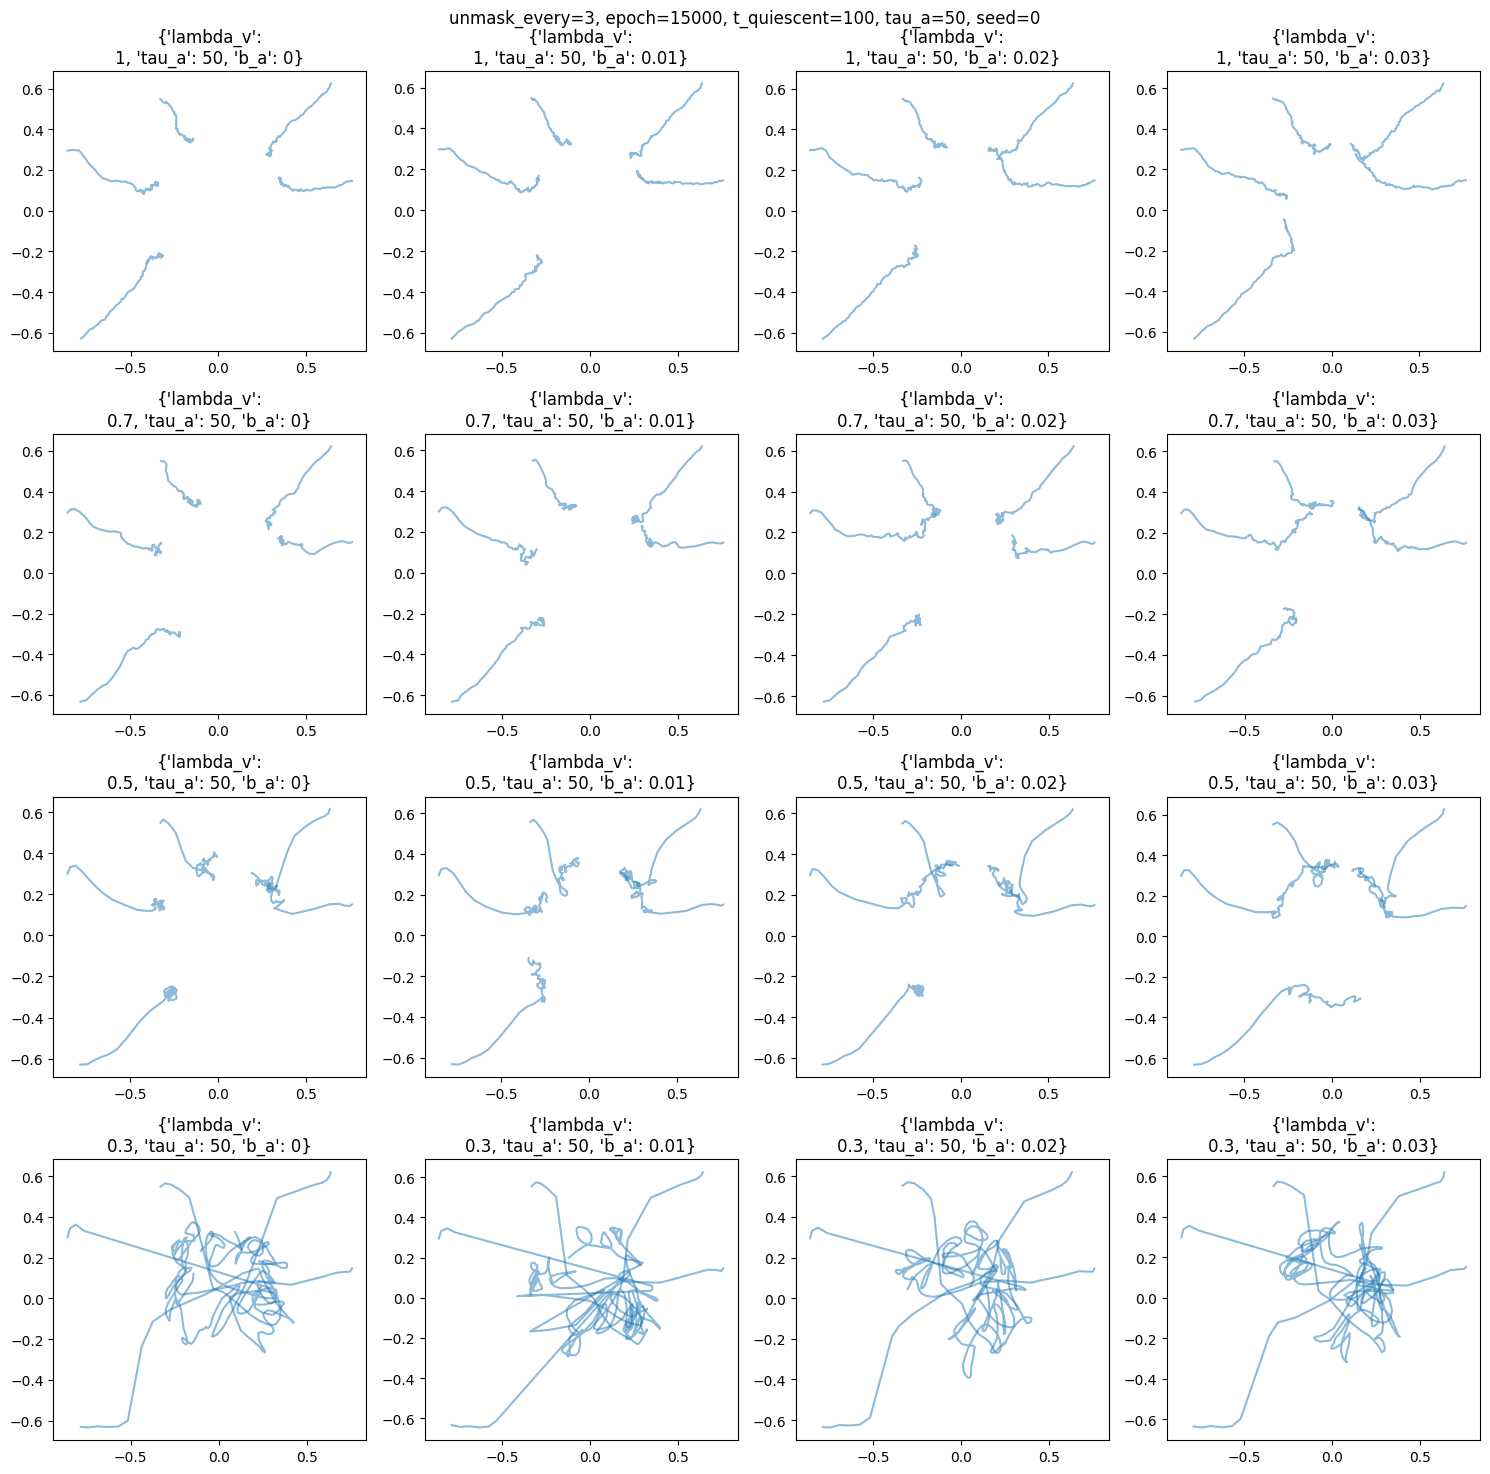

In [11]:
seed_idx = 0
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(15,15))
axs = axs.flatten()
for i,(k,v) in enumerate(replay.items()):
    #plot_pos(axs[i], v, title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
    plot_pos(axs[i], v[seed_idx,:5,:100], title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
fig.suptitle(f'{unmask_every=}, {epoch=}, t_quiescent=100, {tau_a=}, seed={seed_idx}')
fig.tight_layout()

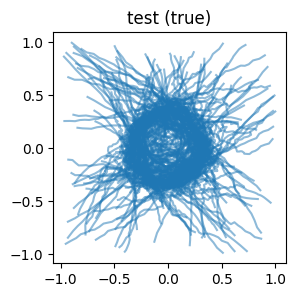

In [12]:
fig, ax = plt.subplots(1,1, figsize=(3,3))
plot_pos(ax, test_pos[seed_idx], title='test (true)')

In [13]:
os.makedirs('../figures', exist_ok=True)

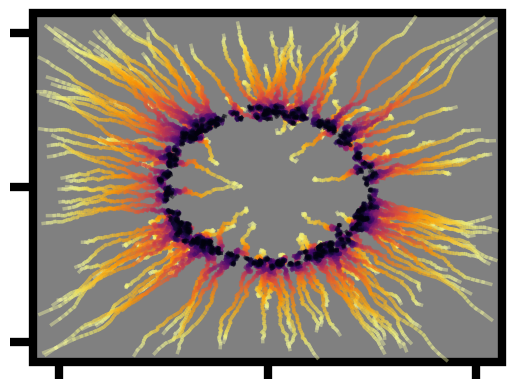

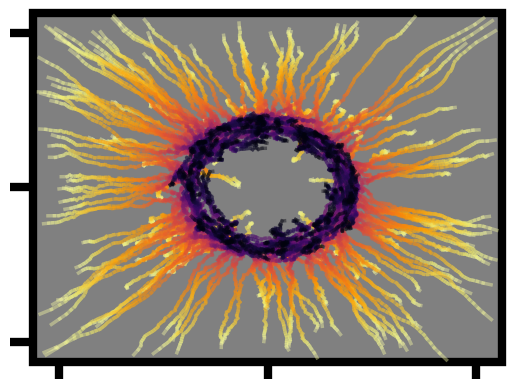

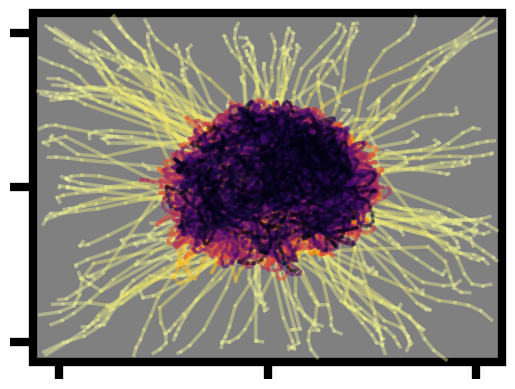

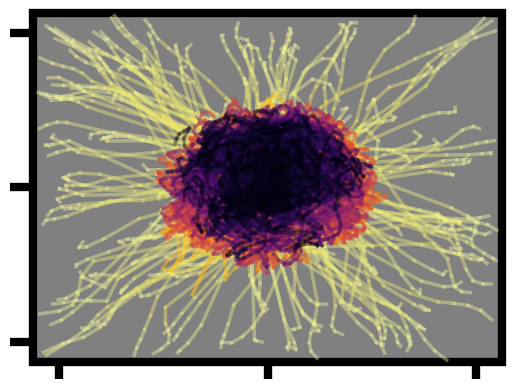

In [14]:
cmap = matplotlib.colormaps['inferno'] # 'plasma'
T_awake = test_pos.shape[2] # 100
xlim=(-0.9,0.9)
ylim=(-0.9,0.9)

for lv in (lambda_v_vals[0], lambda_v_vals[-1]):
    for ba in (b_a_vals[0], b_a_vals[-1]):
        fig, ax = plt.subplots(dpi=100)
        ax.axis('off')
        ax.set(xlim=xlim, ylim=ylim)
        add_border_and_ticks(ax, xlim, ylim, [-0.8,0,0.8], [-0.8,0,0.8],
                             extra_padding=(0.015,0.02)) # gray
        
        #x_hat = test_pos
        x_hat = replay[str({'lambda_v': lv, 'tau_a': tau_a, 'b_a': ba})]
        x_hat = x_hat.flatten(0,1) # combine the seed and sample dimensions
        for t in range(T_awake-1):
            # plot every 10th sample
            ax.plot(x_hat[::10,t:t+2,0].T, x_hat[::10,t:t+2,1].T,
                    c=cmap(1 - t/T_awake), alpha=0.4, linewidth=2.5)#, zorder=T-t)
        fig.savefig(f'../figures/biased_lambda_v={lv},b_a={ba}.png',
                    bbox_inches='tight', pad_inches=0)

### Wasserstein distance

In [15]:
os.makedirs('../csv', exist_ok=True)

In [16]:
wds = calc_wds(replay, test_pos)

100%|███████████████████████████████████████████| 16/16 [00:46<00:00,  2.88s/it]


In [17]:
dict_to_csv(wds, 'b_a', path='../csv/wds_biased.csv')

,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02,b_a=0.03
0,1.0,50,0.124270,0.114823,0.102899,0.089735
1,0.7,50,0.101023,0.095340,0.088548,0.079180
2,0.5,50,0.087406,0.084471,0.081353,0.074790
3,0.3,50,0.089761,0.092155,0.095843,0.097714


## velocities and reach times

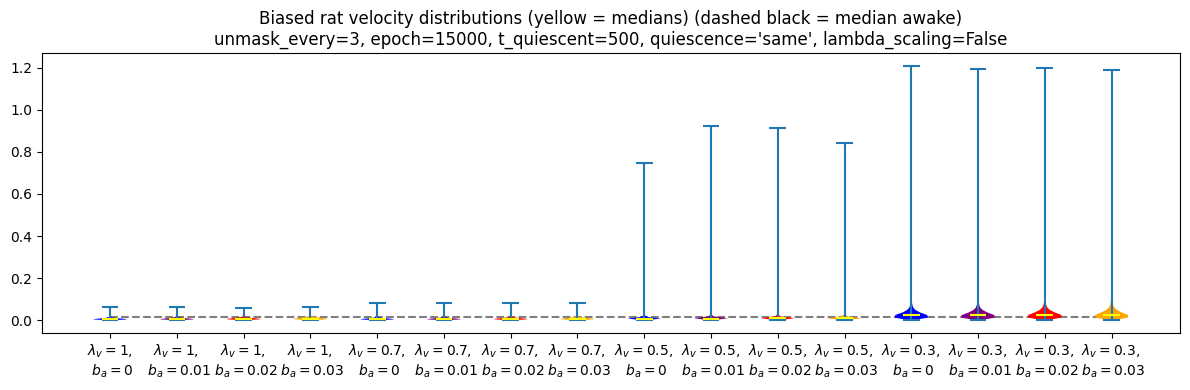

In [18]:
# velocity

xlabels = [f"$\lambda_v={eval(k)['lambda_v']}$, \n $b_a={eval(k)['b_a']}$" \
           for k in replay.keys()]
    
# make sure that the number of timesteps are the same
# shape = seeds, N, T, 2
t_vel = test_pos.shape[2]
replay_vels = {k: v[:, :, :t_vel].diff(dim=2).square().sum(-1).sqrt().flatten() \
               for (k,v) in replay.items()}
test_vels = test_pos.diff(dim=2).square().sum(-1).sqrt().flatten()

violinplot(replay_vels, xlabels)
plt.title('Biased rat velocity distributions (yellow = medians) (dashed black = median awake)' + \
          f'\n{unmask_every=}, {epoch=}, {t_quiescent=}, {quiescence=}, {lambda_scaling=}')
plt.hlines(test_vels.median(), 1, len(xlabels), linestyle='--', color='black', alpha=0.5, zorder=-1)
plt.tight_layout()
plt.show()

In [19]:
inner_radius, outer_radius = 0.2, 0.45

In [20]:
reach_times, rt_meds, rt_avgs = {}, {}, {}
for (k,v) in list(replay.items()) + [('awake', test_pos)]:
    assert v.ndim == 4 # seed, N, T, 2
    radii = v.flatten(0,1).square().sum(-1).sqrt()
    success = ((radii > inner_radius) & (radii < outer_radius)).int()
    assert 0 not in success.sum(1) # make sure the conditions have been met at least once
    reach_times[k] = success.argmax(dim=1)
    rt_meds[k] = reach_times[k].float().median().item()
    rt_avgs[k] = reach_times[k].float().mean().item()
awake_reach_times = reach_times.pop('awake')
awake_rt_med = rt_meds.pop('awake')
awake_rt_avg = rt_avgs.pop('awake')

In [21]:
delta_arrays = {
    'median':  (np.array(list(rt_meds.values())).reshape(4,4) / awake_rt_med - 1) * 100,
    'average': (np.array(list(rt_avgs.values())).reshape(4,4) / awake_rt_avg - 1) * 100
}

print(delta_arrays['median'], '\n')
print(delta_arrays['average'], '\n')
print('min: ', min(delta_arrays['median'].min(), delta_arrays['average'].min()))
print('max: ', max(delta_arrays['median'].max(), delta_arrays['average'].max()))

os.makedirs('../csv/rt', exist_ok=True)
array_to_heatmap(delta_arrays['median'],  '../csv/rt/med_rt_heatmap_biased.txt')
array_to_heatmap(delta_arrays['average'], '../csv/rt/avg_rt_heatmap_biased.txt');

[[291.66666667 233.33333333 200.         175.        ]
 [133.33333333 108.33333333 100.          91.66666667]
 [-33.33333333 -33.33333333 -33.33333333 -33.33333333]
 [-58.33333333 -58.33333333 -58.33333333 -58.33333333]] 

[[170.98048117 128.96931469 103.96345179  86.23840869]
 [ 59.46507658  44.6624086   35.09188928  27.45623738]
 [-39.0118155  -41.26133512 -42.47313651 -44.48833183]
 [-64.5197996  -64.38589955 -64.72399695 -65.23616473]] 

min:  -65.23616473061804
max:  291.66666666666663
Make sure to add newlines before plotting in TikZ
Make sure to add newlines before plotting in TikZ


### Exploration stuff

In [22]:
def calculate_angles(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    angles = torch.atan(x[...,1] / x[...,0])
    dangles = angles.diff(dim=1) # diff along time dimension
    # some logic to undo the angle-wrapping in torch.atan
    dangles[dangles < -torch.pi/2] += torch.pi
    dangles[dangles > torch.pi/2] -= torch.pi
    angles = angles[:,0:1] + \
             torch.cat((torch.zeros(len(angles), 1), dangles.cumsum(dim=1)), dim=1)
    return angles, dangles

def calculate_path_lens(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # differentiate along T (dim 1),
    # calculate dx (square sum sqrt),
    # sum along T (now dim -1)
    return x.diff(dim=1).square().sum(-1).sqrt().sum(-1)

def calculate_mean_displacements(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # subtract x wrt x(t=0) (time is dim 1),
    # calculate distance (square, sum, sqrt),
    # take mean along samples (dim 0)
    return (x - x[:,0:1]).square().sum(-1).sqrt().mean(0)

def calculate_variances(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # calculate variance of x along samples, take mean along dimensions.
    # the output should be a vector of length = # timestpes (dim 1)
    return x.var(0).mean(-1)

dist_avg, dist_std, dist_all, angl_avg, angl_std, md, variances = {}, {}, {}, {}, {}, {}, {}
for k, x_hat in replay.items():
    # combine seed and sample dim. x_hat shape = (-1, timesteps, 2)
    x_hat = x_hat.flatten(0,1)
    _, dangles = calculate_angles(x_hat)
    path_lens = calculate_path_lens(x_hat)

    # populate the dicts
    dist_avg[k] = path_lens.mean().item()
    dist_std[k] = path_lens.sum(-1).std().item()
    dist_all[k] = path_lens
    angl_avg[k] = dangles.abs().sum(-1).mean().item()
    angl_std[k] = dangles.abs().sum(-1).std().item()
    md[k] = calculate_mean_displacements(x_hat)
    variances[k] = calculate_variances(x_hat)

In [23]:
print("Distance p-values:")
p = {k: ttest_rel(list(dist_all.values())[0], v).pvalue
     for (k,v) in dist_all.items()}
p

Distance p-values:


{"{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}": nan,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.02}": 0.0,
 "{'lambda_v': 1, 'tau_a': 50, 'b_a': 0.03}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.02}": 0.0,
 "{'lambda_v': 0.7, 'tau_a': 50, 'b_a': 0.03}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.02}": 0.0,
 "{'lambda_v': 0.5, 'tau_a': 50, 'b_a': 0.03}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.01}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.02}": 0.0,
 "{'lambda_v': 0.3, 'tau_a': 50, 'b_a': 0.03}": 0.0}

In [24]:
print("Values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

Values above 0.05:


{}

In [25]:
os.makedirs('../csv/exploration', exist_ok=True)
print(calculate_path_lens(test_pos.flatten(0,1)).mean().item())
dict_to_csv(dist_avg, col_param='b_a', path='../csv/exploration/exploration_distance_biased.csv')

1.7288973331451416


,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02,b_a=0.03
0,1.0,50,2.574687,2.774128,2.996569,3.282833
1,0.7,50,2.893939,3.055226,3.225735,3.469948
2,0.5,50,3.801629,3.966177,4.116535,4.332893
3,0.3,50,17.380730,19.246603,20.934233,22.664553
